[![preview notebook](https://img.shields.io/static/v1?label=render%20on&logo=github&color=87ce3e&message=GitHub)](https://github.com/open-atmos/PySDM/blob/main/examples/PySDM_examples/featured/Long_1974/figs_10_11_13_14.ipynb)
[![launch on mybinder.org](https://mybinder.org/badge_logo.svg)](https://mybinder.org/v2/gh/open-atmos/PySDM.git/main?urlpath=lab/tree/examples/PySDM_examples/featured/Long_1974/figs_10_11_13_14.ipynb)
[![launch on Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/open-atmos/PySDM/blob/main/examples/PySDM_examples/featured/Long_1974/figs_10_11_13_14.ipynb)

#### based on Fig. 10-11 (continental cloud) and 13-14 (maritime cloud) from Long 1974 (Journal of the Amotphseric Sciences 31)  "_Solutions to the droplet collection equation for polynomial kernels_", includes the proposed piecewise Long kernel (eq 11) as well as the Safranov-Golovin Kernel (Eq 3b)

[doi:10.1175/1520-0469%281974%29031%3C1040%3ASTTDCE%3E2.0.CO%3B2](https://doi.org/10.1175/1520-0469%281974%29031%3C1040%3ASTTDCE%3E2.0.CO%3B2)

In [1]:
import os, sys
os.environ['NUMBA_THREADING_LAYER'] = 'workqueue'  # PySDM & PyMPDATA don't work with TBB; OpenMP has extra dependencies on macOS
if 'google.colab' in sys.modules:
    !pip --quiet install open-atmos-jupyter-utils
    from open_atmos_jupyter_utils import pip_install_on_colab
    pip_install_on_colab('PySDM-examples', 'PySDM')

In [2]:
import numpy as np
from PySDM_examples.featured.Long_1974 import Settings, Simulation
from PySDM.physics import si
from PySDM.dynamics.collisions.collision_kernels import Long1974, Golovin
import matplotlib.pyplot as plt
from open_atmos_jupyter_utils import show_plot

In [3]:
CI = 'CI' in os.environ

def simulate(*,
    bins_r_min=5.0 * si.um,
    n_sd = 2**(16 if not CI else 12),
    bins_r_max,
    output_interval,
    n_part,
    t_max,
):
    output = {'radius_bins_edges': np.logspace(
        np.log10(bins_r_min / si.m), np.log10(bins_r_max / si.m), num=64, endpoint=True
    )}
    output['settingsL'] = Settings(
        kernel = Long1974(),
        output_interval = output_interval,
        n_part = n_part,
        radius_bins_edges=output['radius_bins_edges'],
        n_sd = n_sd,
        t_max = t_max,
    )
    output['L'] = Simulation(output['settingsL']).run()
    
    output['settingsG'] = Settings(
        kernel = Golovin(b=1.5e3 / si.second),
        output_interval = output_interval,
        n_part = n_part,
        radius_bins_edges=output['radius_bins_edges'],
        n_sd = n_sd,
        t_max = t_max,
    )
    output['G'] = Simulation(output['settingsG']).run()
    return output


def plot(output, fname):
    fig, ax = plt.subplots(figsize=(6, 4))
    lsL = '-'
    lsG = '-.'
    
    for it in (0, 1, 3):
        t = output['settingsG'].output_interval * it
        lL = ax.plot(
            output['radius_bins_edges'][:-1] / si.um, 
            output['L']['dv/dlnr'][it] * output['settingsL'].rho / si.g, 
            label=f'Long, t={t}s',
            ls=lsL)
        ax.plot(
            output['radius_bins_edges'][:-1] / si.um, 
            output['G']['dv/dlnr'][it] * output['settingsG'].rho / si.g, 
            label=f'B(x+y), t={t}s',
            ls=lsG,
            color=lL[-1].get_color())
    ax.set_xlabel('$R$ (μm)')
    ax.set_ylabel('$dv$/$d$ln$r$ (g/m$^3$)')
    ax.set_xscale('log')
    plt.legend()
    show_plot(fname)
    plt.close(fig)

## Fig 10-11: Continental Aerosol

In [4]:
fig_10_11_data = simulate(
    bins_r_max=200 * si.um,
    output_interval=600 * si.s,
    n_part = 200 / si.cm**3,
    t_max = 1800 * si.s,
)

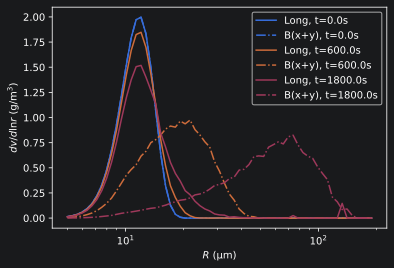

In [5]:
plot(fig_10_11_data, 'fig_10-11')

## Fig 13-14: Marine Aerosol

In [6]:
fig_13_14_data = simulate(
    bins_r_max=400 * si.um,
    output_interval = 300 * si.s,
    n_part = 50 / si.cm**3,
    t_max = 900 * si.s,
)

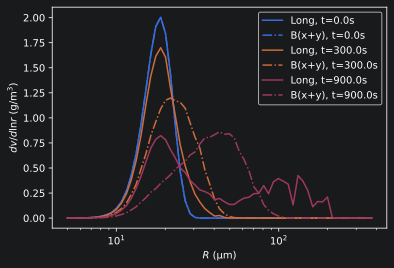

In [7]:
plot(fig_13_14_data, 'fig_13-14')